In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

os.makedirs("outputs/figures", exist_ok=True)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


### Load Titanic

In [4]:
df = sns.load_dataset("titanic")

print("Dataset loaded successfully.")

df.to_csv(
    "titanic.csv",
    index=False
)

print("Offline fallback saved to titanic.csv")

Dataset loaded successfully.
Offline fallback saved to titanic.csv


### Initial profiling

In [5]:
print("=" * 60)
print("DATASET SHAPE")
print("=" * 60)

print(df.shape)

print("\n" + "=" * 60)
print("DATASET INFO")
print("=" * 60)

df.info()

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS")
print("=" * 60)

print(df.describe(include="all").transpose())

DATASET SHAPE
(891, 15)

DATASET INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB

DESCRIPTIVE STATISTICS
             coun

### Missing-value percentages

In [7]:
missing = (
    df.isnull()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

missing = missing[missing > 0]

print("Missing-value percentages:")
print(missing)

with open(
    "outputs/eda_results.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write("MISSING VALUE PERCENTAGES\n")
    f.write("=" * 50 + "\n")
    f.write(missing.to_string())
    f.write("\n")

Missing-value percentages:
deck           77.216611
age            19.865320
embarked        0.224467
embark_town     0.224467
dtype: float64


### the required threshold rule

In [12]:
cleaned_df = df.copy()

cleaning_decisions = []

for column in df.columns:

    missing_pct = df[column].isna().mean() * 100

    if missing_pct == 0:
        continue

    if missing_pct < 5:

        cleaning_decisions.append(
            (
                column,
                missing_pct,
                "Drop rows"
            )
        )

    elif missing_pct <= 30:

        cleaning_decisions.append(
            (
                column,
                missing_pct,
                "Impute"
            )
        )

    else:

        cleaning_decisions.append(
            (
                column,
                missing_pct,
                "Drop column"
            )
        )


cleaning_decisions_df = pd.DataFrame(
    cleaning_decisions,
    columns=[
        "column",
        "missing_percentage",
        "strategy"
    ]
)

print(cleaning_decisions_df)


for column, missing_pct, strategy in cleaning_decisions:

    if strategy == "Drop rows":

        cleaned_df = cleaned_df.dropna(
            subset=[column]
        )

    elif strategy == "Impute":

        if pd.api.types.is_numeric_dtype(
            cleaned_df[column]
        ):

            cleaned_df[column] = (
                cleaned_df[column]
                .fillna(
                    cleaned_df[column].median()
                )
            )

        else:

            # Convert categorical column to object
            # before filling with a new value.
            if isinstance(
                cleaned_df[column].dtype,
                pd.CategoricalDtype
            ):
                cleaned_df[column] = (
                    cleaned_df[column]
                    .astype("object")
                )

            cleaned_df[column] = (
                cleaned_df[column]
                .fillna(
                    cleaned_df[column].mode()[0]
                )
            )

    elif strategy == "Drop column":

        cleaned_df = cleaned_df.drop(
            columns=[column]
        )

cleaning_decisions_df.to_csv(
    "outputs/cleaning_decisions.csv",
    index=False
)

print("\nCleaning decisions:")
print(
    cleaning_decisions_df.to_string(
        index=False
    )
)

        

        column  missing_percentage     strategy
0          age           19.865320       Impute
1     embarked            0.224467    Drop rows
2         deck           77.216611  Drop column
3  embark_town            0.224467    Drop rows

Cleaning decisions:
     column  missing_percentage    strategy
        age           19.865320      Impute
   embarked            0.224467   Drop rows
       deck           77.216611 Drop column
embark_town            0.224467   Drop rows


### Verify cleaning

In [14]:
print("Original shape:", df.shape)
print("Cleaned shape:", cleaned_df.shape)

print("\nRemaining missing values:")

remaining_missing = (
    cleaned_df.isnull()
    .sum()
)

print(
    remaining_missing[
        remaining_missing > 0
    ]
)

Original shape: (891, 15)
Cleaned shape: (889, 14)

Remaining missing values:
Series([], dtype: int64)


### Age histogram

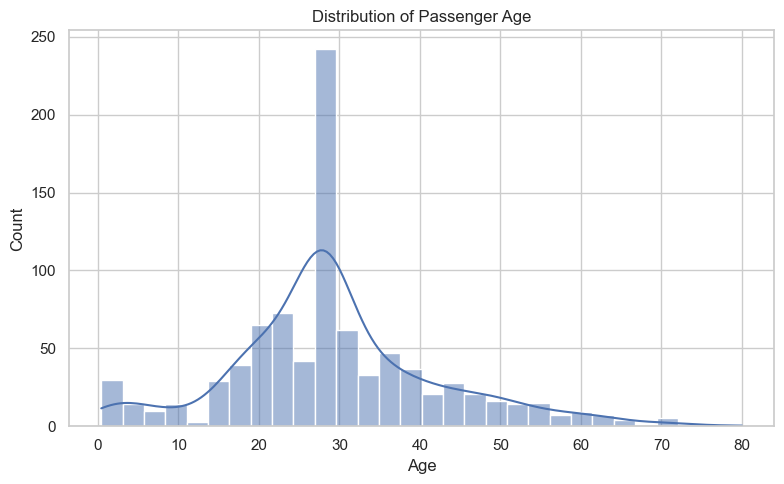

In [15]:
plt.figure(figsize=(8, 5))

sns.histplot(
    cleaned_df["age"],
    kde=True
)

plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Count")

plt.tight_layout()

plt.savefig(
    "outputs/figures/age_histogram.png",
    dpi=300
)

plt.show()

### Age boxplot

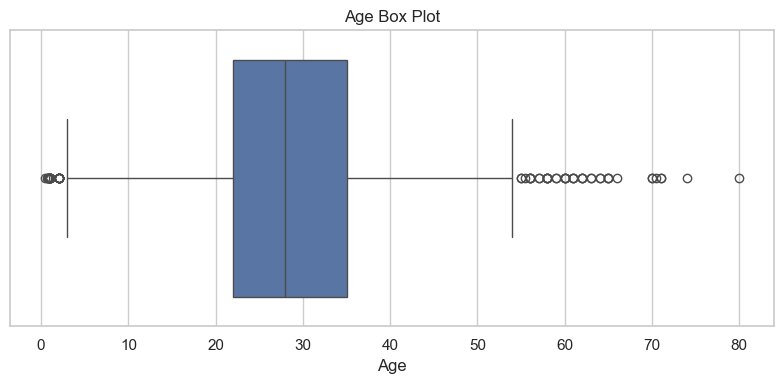

In [16]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    x=cleaned_df["age"]
)

plt.title("Age Box Plot")
plt.xlabel("Age")

plt.tight_layout()

plt.savefig(
    "outputs/figures/age_boxplot.png",
    dpi=300
)

plt.show()

### Fare histogram

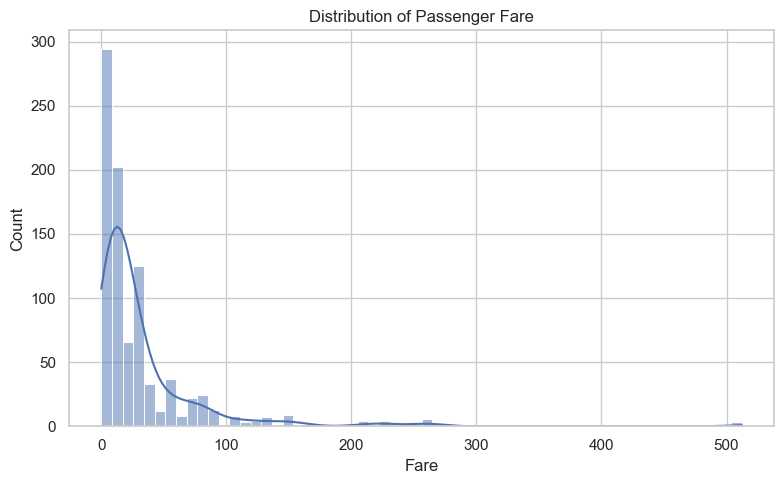

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(
    cleaned_df["fare"],
    kde=True
)

plt.title("Distribution of Passenger Fare")
plt.xlabel("Fare")
plt.ylabel("Count")

plt.tight_layout()

plt.savefig(
    "outputs/figures/fare_histogram.png",
    dpi=300
)

plt.show()

### Fare boxplot

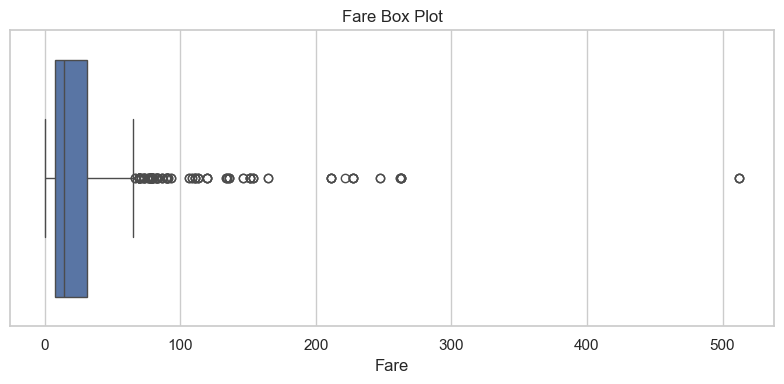

In [18]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    x=cleaned_df["fare"]
)

plt.title("Fare Box Plot")
plt.xlabel("Fare")

plt.tight_layout()

plt.savefig(
    "outputs/figures/fare_boxplot.png",
    dpi=300
)

plt.show()

### IQR outlier calculation

In [19]:
def iqr_outlier_count(series):

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = (
        (series < lower) |
        (series > upper)
    )

    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(outliers.sum())
    }


age_outliers = iqr_outlier_count(
    cleaned_df["age"]
)

fare_outliers = iqr_outlier_count(
    cleaned_df["fare"]
)

print("AGE OUTLIERS")
print(age_outliers)

print("\nFARE OUTLIERS")
print(fare_outliers)

AGE OUTLIERS
{'Q1': np.float64(22.0), 'Q3': np.float64(35.0), 'IQR': np.float64(13.0), 'lower_bound': np.float64(2.5), 'upper_bound': np.float64(54.5), 'outlier_count': 65}

FARE OUTLIERS
{'Q1': np.float64(7.8958), 'Q3': np.float64(31.0), 'IQR': np.float64(23.1042), 'lower_bound': np.float64(-26.7605), 'upper_bound': np.float64(65.6563), 'outlier_count': 114}


### Fare mean, median, mode

In [21]:
fare_mean = cleaned_df["fare"].mean()

fare_median = cleaned_df["fare"].median()

fare_mode = (
    cleaned_df["fare"]
    .mode()
    .iloc[0]
)

print("Fare mean:", fare_mean)
print("Fare median:", fare_median)
print("Fare mode:", fare_mode)

if fare_mean > fare_median > fare_mode:
    fare_skewness = "right-skewed"

elif fare_mean < fare_median < fare_mode:
    fare_skewness = "left-skewed"

else:
    fare_skewness = "approximately symmetric / mixed"

print(
    "Fare distribution:",
    fare_skewness
)

Fare mean: 32.09668087739032
Fare median: 14.4542
Fare mode: 8.05
Fare distribution: right-skewed


### Survival by sex

In [22]:
survival_by_sex = (
    cleaned_df
    .groupby("sex")["survived"]
    .mean()
    .mul(100)
    .reset_index(
        name="survival_rate_percent"
    )
)

print(survival_by_sex)

      sex  survival_rate_percent
0  female              74.038462
1    male              18.890815


### Survival by class

In [23]:
survival_by_pclass = (
    cleaned_df
    .groupby("pclass")["survived"]
    .mean()
    .mul(100)
    .reset_index(
        name="survival_rate_percent"
    )
)

print(survival_by_pclass)

   pclass  survival_rate_percent
0       1              62.616822
1       2              47.282609
2       3              24.236253


### Sex + class

In [24]:
survival_by_sex_class = (
    cleaned_df
    .groupby(
        ["sex", "pclass"]
    )["survived"]
    .mean()
    .mul(100)
    .reset_index(
        name="survival_rate_percent"
    )
)

print(survival_by_sex_class)

      sex  pclass  survival_rate_percent
0  female       1              96.739130
1  female       2              92.105263
2  female       3              50.000000
3    male       1              36.885246
4    male       2              15.740741
5    male       3              13.544669


### Boolean masking

In [25]:
female_first_class = cleaned_df[
    (cleaned_df["sex"] == "female") &
    (cleaned_df["pclass"] == 1)
]

female_first_class_survival = (
    female_first_class["survived"].mean()
    * 100
)

print(
    "Female + First Class survival rate:",
    female_first_class_survival
)

Female + First Class survival rate: 96.73913043478261


### Exact correlation matrix

          survived    pclass       age     sibsp     parch      fare
survived  1.000000 -0.335549 -0.069822 -0.034040  0.083151  0.255290
pclass   -0.335549  1.000000 -0.336512  0.081656  0.016824 -0.548193
age      -0.069822 -0.336512  1.000000 -0.232543 -0.171485  0.093707
sibsp    -0.034040  0.081656 -0.232543  1.000000  0.414542  0.160887
parch     0.083151  0.016824 -0.171485  0.414542  1.000000  0.217532
fare      0.255290 -0.548193  0.093707  0.160887  0.217532  1.000000


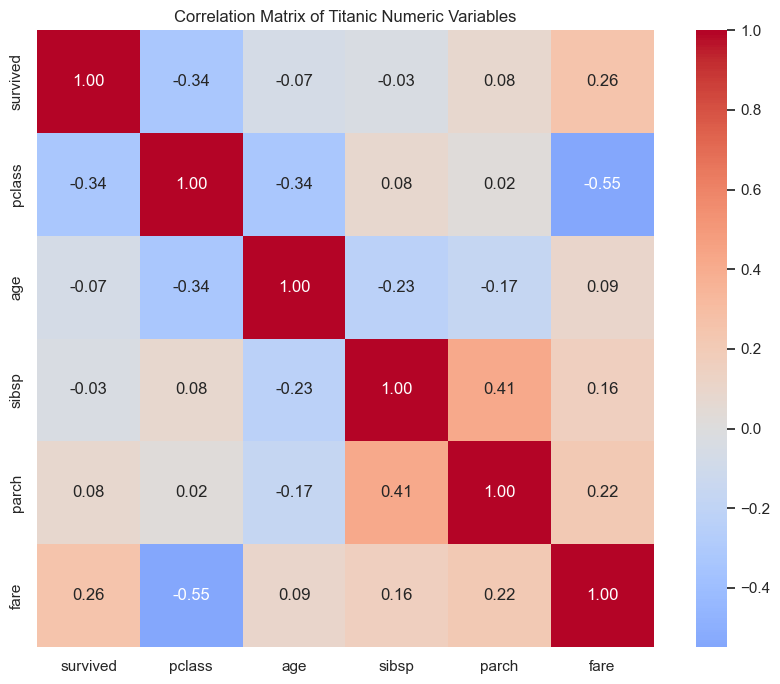

In [26]:
correlation_columns = [
    "survived",
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]

correlation_matrix = (
    cleaned_df[
        correlation_columns
    ].corr()
)

print(correlation_matrix)

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title(
    "Correlation Matrix of Titanic Numeric Variables"
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/correlation_heatmap.png",
    dpi=300
)

plt.show()

### Find the two strongest correlations automatically

In [27]:
corr_pairs = []

for i in range(
    len(correlation_columns)
):

    for j in range(
        i + 1,
        len(correlation_columns)
    ):

        feature_1 = correlation_columns[i]
        feature_2 = correlation_columns[j]

        correlation = (
            correlation_matrix
            .loc[
                feature_1,
                feature_2
            ]
        )

        corr_pairs.append(
            {
                "feature_1": feature_1,
                "feature_2": feature_2,
                "correlation": correlation,
                "absolute_correlation":
                    abs(correlation)
            }
        )

strongest_correlations = (
    pd.DataFrame(corr_pairs)
    .sort_values(
        "absolute_correlation",
        ascending=False
    )
    .head(2)
)

print(
    strongest_correlations
)

   feature_1 feature_2  correlation  absolute_correlation
8     pclass      fare    -0.548193              0.548193
12     sibsp     parch     0.414542              0.414542


### Chart 1 — Sex + class survival

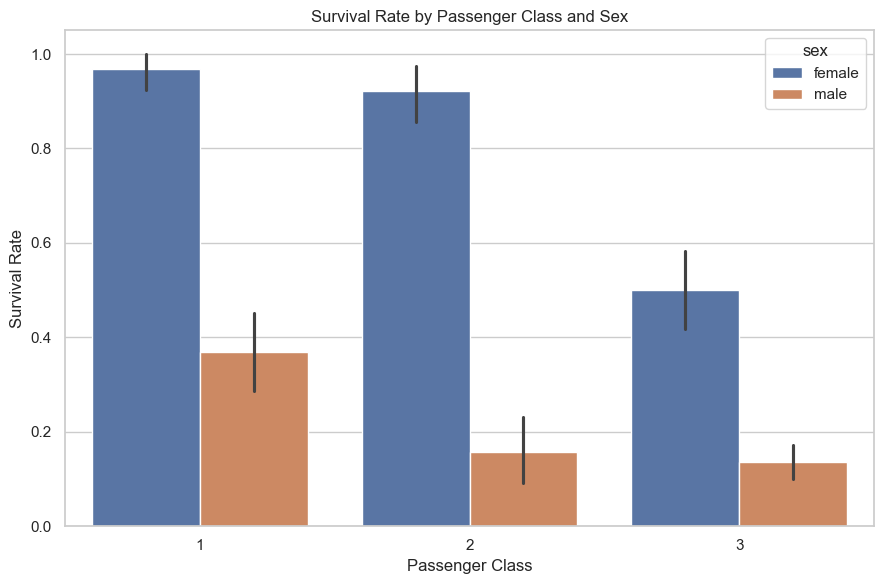

In [28]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=cleaned_df,
    x="pclass",
    y="survived",
    hue="sex"
)

plt.title(
    "Survival Rate by Passenger Class and Sex"
)

plt.ylabel("Survival Rate")

plt.xlabel("Passenger Class")

plt.tight_layout()

plt.savefig(
    "outputs/figures/survival_sex_class.png",
    dpi=300
)

plt.show()

Interpretation:

Survival varied substantially by both sex and passenger class. Female passengers generally had higher survival rates than male passengers, while first-class passengers generally had better outcomes than passengers in lower classes. This indicates that both gender and socioeconomic position were important factors associated with survival.

### Chart 2 — Age vs survival

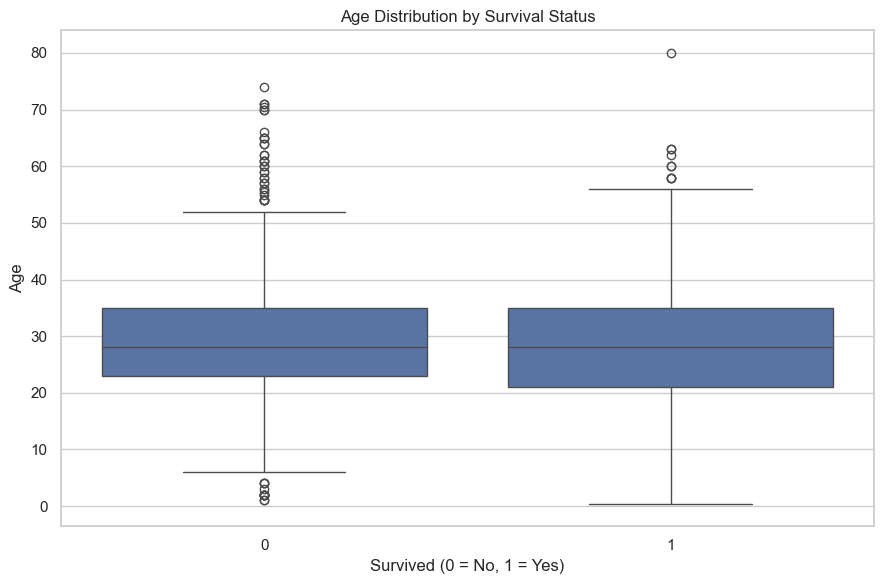

In [29]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=cleaned_df,
    x="survived",
    y="age"
)

plt.title(
    "Age Distribution by Survival Status"
)

plt.xlabel(
    "Survived (0 = No, 1 = Yes)"
)

plt.ylabel("Age")

plt.tight_layout()

plt.savefig(
    "outputs/figures/age_survival.png",
    dpi=300
)

plt.show()

Interpretation:

The age distributions of survivors and non-survivors overlap substantially, indicating that age alone does not fully explain survival. However, differences in the distributions suggest that age contributed to survival outcomes alongside other demographic and socioeconomic variables.

### Chart 3 — Fare vs survival

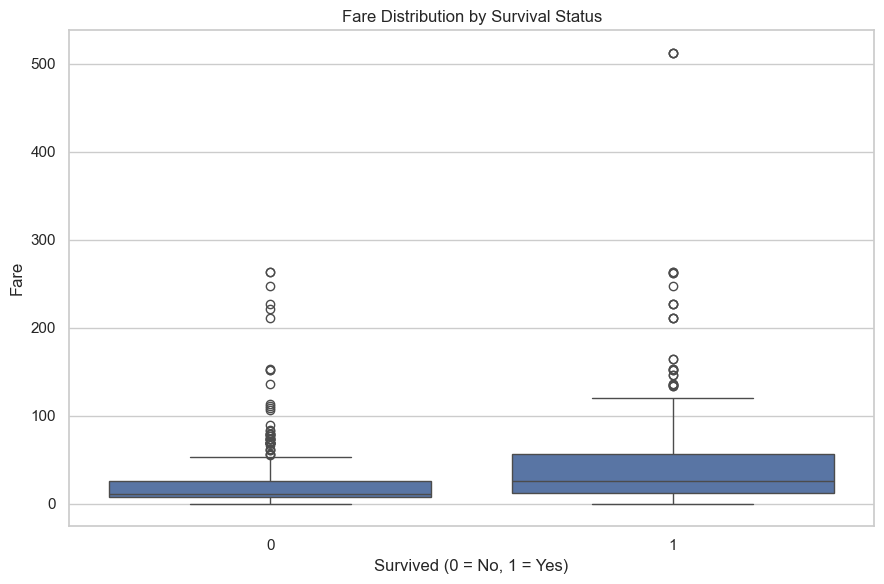

In [30]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=cleaned_df,
    x="survived",
    y="fare"
)

plt.title(
    "Fare Distribution by Survival Status"
)

plt.xlabel(
    "Survived (0 = No, 1 = Yes)"
)

plt.ylabel("Fare")

plt.tight_layout()

plt.savefig(
    "outputs/figures/fare_survival.png",
    dpi=300
)

plt.show()

Interpretation:

Survivors tend to show a higher fare distribution than non-survivors. This is consistent with the relationship between fare and passenger class, suggesting that socioeconomic status was associated with survival probability.

### Chart 4 — Age/Fare/Survival

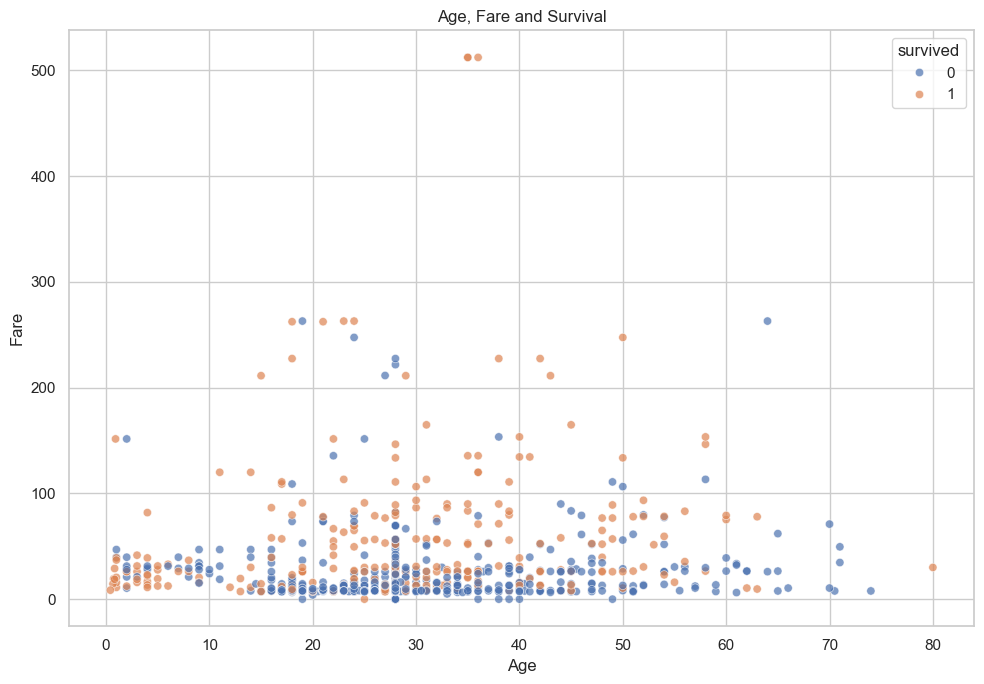

In [31]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=cleaned_df,
    x="age",
    y="fare",
    hue="survived",
    alpha=0.7
)

plt.title(
    "Age, Fare and Survival"
)

plt.xlabel("Age")

plt.ylabel("Fare")

plt.tight_layout()

plt.savefig(
    "outputs/figures/age_fare_survival.png",
    dpi=300
)

plt.show()

Interpretation:

The scatter plot shows the interaction between age, fare and survival rather than examining each variable independently. Higher-fare passengers appear in different survival patterns than low-fare passengers, while age adds another dimension to the distribution. This supports the conclusion that Titanic survival was influenced by multiple interacting characteristics rather than a single variable.

### Standardization sanity check

In [32]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

standardized = cleaned_df[
    ["age", "fare"]
].copy()

standardized[
    ["age", "fare"]
] = scaler.fit_transform(
    standardized[
        ["age", "fare"]
    ]
)

print("BEFORE STANDARDIZATION")
print(
    cleaned_df[
        ["age", "fare"]
    ].agg(
        ["mean", "std"]
    )
)

print("\nAFTER STANDARDIZATION")
print(
    standardized[
        ["age", "fare"]
    ].agg(
        ["mean", "std"]
    )
)

BEFORE STANDARDIZATION
            age       fare
mean  29.315152  32.096681
std   12.984932  49.697504

AFTER STANDARDIZATION
               age          fare
mean  2.717486e-16  1.398706e-16
std   1.000563e+00  1.000563e+00
